# Photometry-prefit quality review

This notebook reads completed stage-1 checkpoints only; it never re-fits a system.  It selects a reproducible random sample, shows an event-centred light-curve grid, and provides individual light-curve and corner-plot diagnostics.  The retained samples are approximate scheduling posteriors, so corner plots are useful for detecting obvious pathologies rather than for convergence claims.

In [1]:
import os
import sys
from pathlib import Path

# Keep this review kernel off the GPU used by the running stage-1 job.
os.environ.setdefault('JAX_PLATFORMS', 'cpu')
sys.path.insert(0, str(Path.cwd() / 'src'))

import corner
import jax.numpy as jnp
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from fitting import PREFIT_RESULTS_PATH
from prefit import (
    PREFIT_PARAMETER_NAMES, bin_full_lightcurve_hourly, load_lightcurve,
    prefit_bin_width_days,
)
from selflensing.lightcurves import PARAMETER_ORDER, light_curve_amplification

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})

2026-08-26 17:27:33,323 DEBUG [utils] Logging configured at DEBUG
2026-08-26 17:27:33,333 DEBUG [utils] Data path initialised at /scratch/anm1u24/self_lensing_radial_velocity/data


In [2]:
SAMPLE_SIZE = 100
RANDOM_SEED = 20260825

prefits = pd.read_pickle(PREFIT_RESULTS_PATH)
prefits = prefits[prefits['prefit_posterior_path'].map(lambda path: Path(path).exists())].copy()
if prefits.empty:
    raise RuntimeError(f'No completed prefits found in {PREFIT_RESULTS_PATH}')

sample_size = min(SAMPLE_SIZE, len(prefits))
review = prefits.sample(sample_size, random_state=RANDOM_SEED).reset_index(drop=True)
print(f'Reviewing {len(review)} of {len(prefits)} completed photometry prefits')
review[['simulation_id', 'prefit_posterior_quality', 'prefit_posterior_path']].head()

Reviewing 100 of 3203 completed photometry prefits


,simulation_id,prefit_posterior_quality,prefit_posterior_path
0,simulation_001084,approximate_random_walk,/home/anm1u24/Code/self_lensing_radial_velocit...
1,simulation_000873,approximate_random_walk,/home/anm1u24/Code/self_lensing_radial_velocit...
2,simulation_000415,approximate_random_walk,/home/anm1u24/Code/self_lensing_radial_velocit...
3,simulation_001721,approximate_random_walk,/home/anm1u24/Code/self_lensing_radial_velocit...
4,simulation_002638,approximate_random_walk,/home/anm1u24/Code/self_lensing_radial_velocit...


In [3]:
LABELS = [r'$a$ [au]', r'$i$ [rad]', r'$M_{\rm lens}$ [$M_\odot$]', r'$e$', r'$\phi_{\rm peri}$ [rad]']
_cache = {}

def parameter_vector(row, prefix='prefit_fitted_'):
    return np.asarray([row[f'{prefix}{name}'] for name in PREFIT_PARAMETER_NAMES], dtype=float)

def map_parameter_vector(row):
    """Highest-posterior retained sample, for a coherent preview model."""
    with np.load(row['prefit_posterior_path']) as data:
        chain = np.asarray(data['chain'], dtype=float)
        log_prob = np.asarray(data['log_prob'], dtype=float)
        names = [str(name) for name in data['parameter_names']]
    samples = chain.reshape((-1, chain.shape[-1]))
    log_prob = log_prob.reshape(-1)
    valid = np.isfinite(log_prob) & np.all(np.isfinite(samples), axis=1)
    if not np.any(valid):
        return parameter_vector(row)
    sample = samples[np.flatnonzero(valid)[np.argmax(log_prob[valid])]]
    return sample[[names.index(name) for name in PREFIT_PARAMETER_NAMES]]

def truth_vector(row):
    return np.asarray([row[name] for name in PREFIT_PARAMETER_NAMES], dtype=float)

def full_parameter_vector(row, fitted):
    values = dict(zip(PREFIT_PARAMETER_NAMES, fitted))
    values.update({name: float(row[name]) for name in ('Mcomp', 'Rcomp', 'Teff')})
    return np.asarray([values[name] for name in PARAMETER_ORDER], dtype=float)

def model_flux(row, times, fitted):
    return np.asarray(light_curve_amplification(
        jnp.asarray(times),
        jnp.asarray(full_parameter_vector(row, fitted)),
        float(row['peak_time']),
    )) - 1.0

def curve_data(row):
    key = str(row['simulation_id'])
    if key not in _cache:
        raw_curve = load_lightcurve(row)
        bin_width_days = prefit_bin_width_days(row['tau_eff'])
        binned = bin_full_lightcurve_hourly(
            raw_curve, bin_width_days=bin_width_days
        )
        valid = binned['mask']
        times = binned['times'][valid]
        def binned_model(fitted):
            model_curve = dict(raw_curve)
            model_curve['flux'] = model_flux(row, raw_curve['times'], fitted)
            return bin_full_lightcurve_hourly(
                model_curve, bin_width_days=bin_width_days
            )['flux'][valid]
        _cache[key] = {
            'times': times,
            'flux': binned['flux'][valid],
            'err': binned['err'][valid],
            'fit_model': binned_model(map_parameter_vector(row)),
            'truth_model': binned_model(truth_vector(row)),
        }
    return _cache[key]

def posterior_samples(row):
    with np.load(row['prefit_posterior_path']) as data:
        samples = np.asarray(data['flat_chain'] if 'flat_chain' in data.files else data['chain'], dtype=float)
        names = [str(name) for name in data['parameter_names']]
    if samples.ndim == 3:
        samples = samples.reshape((-1, samples.shape[-1]))
    samples = samples[:, [names.index(name) for name in PREFIT_PARAMETER_NAMES]]
    return samples[np.all(np.isfinite(samples), axis=1)]

Text(0.5, 1.01, 'Random photometry-prefit review: crossing-time-binned data, MAP prefit (red), truth (blue dashed)')

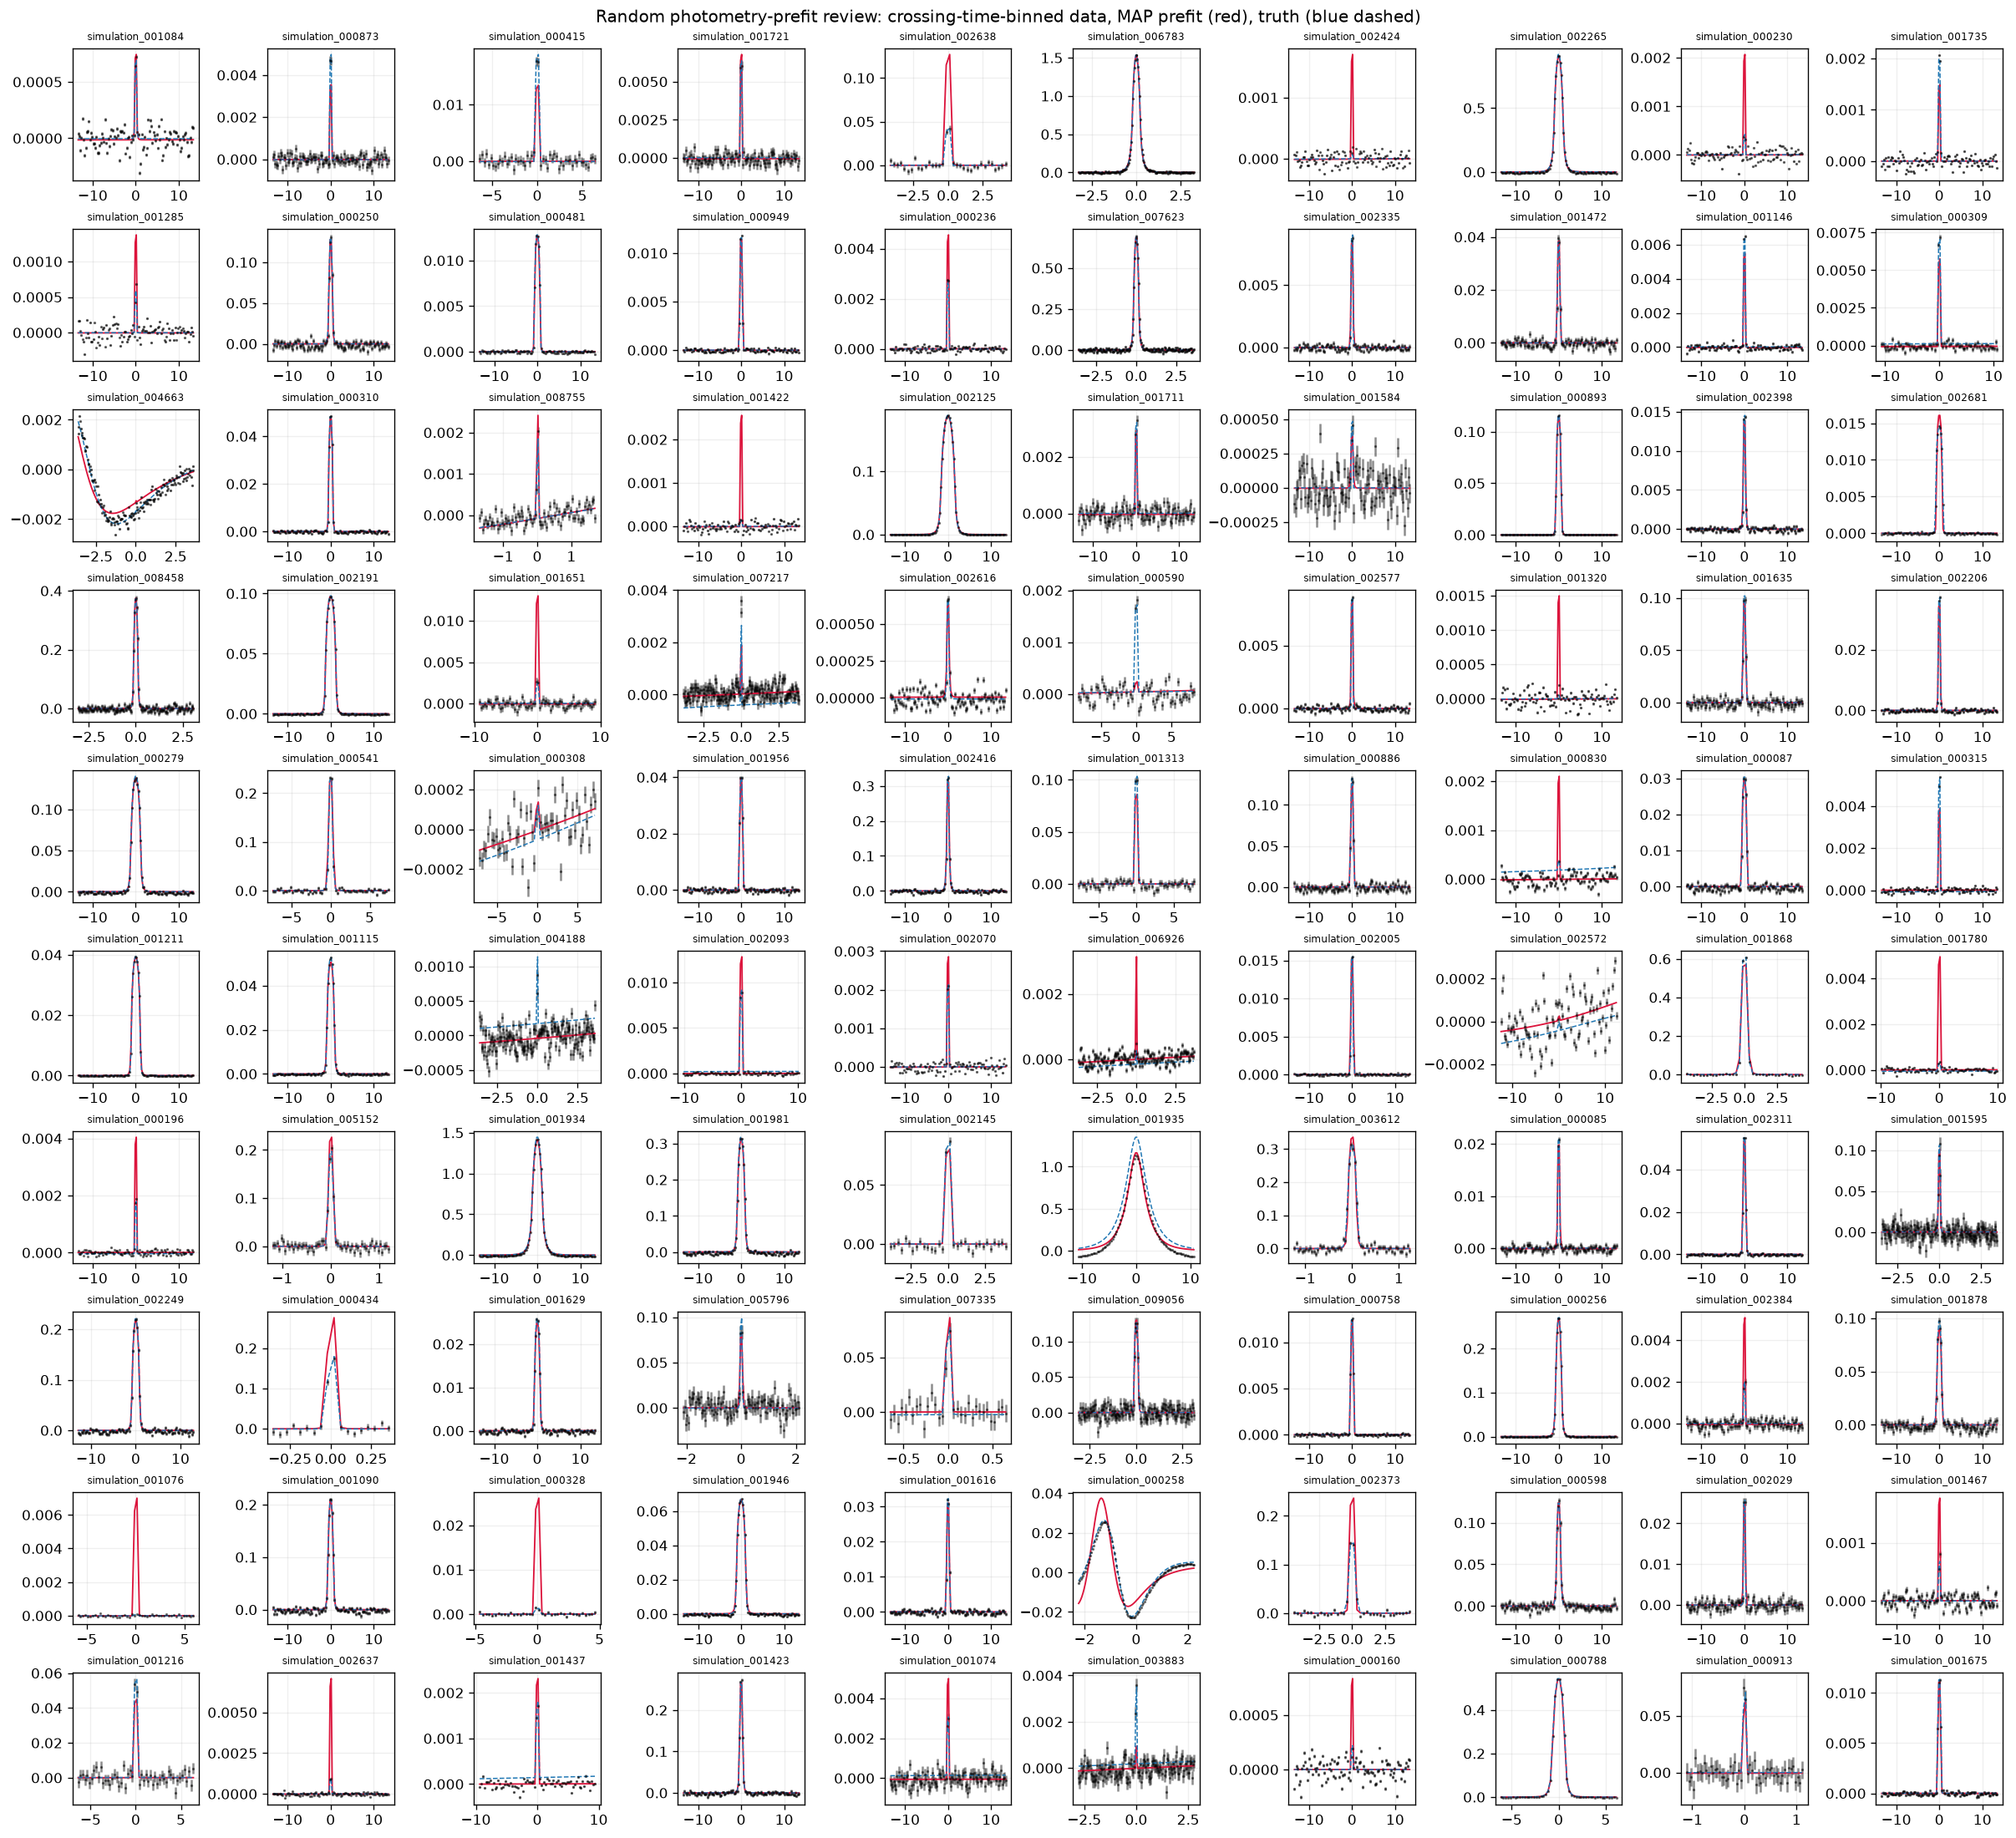

In [4]:
def plot_event(ax, row, show_labels=True):
    data = curve_data(row)
    offset = data['times'] - float(row['peak_time'])
    window = max(0.25, 4.0 * float(row['tau_eff']))
    keep = np.abs(offset) <= window
    ax.errorbar(offset[keep], data['flux'][keep], yerr=data['err'][keep], fmt='.', ms=2, alpha=0.45, color='black')
    ax.plot(offset[keep], data['fit_model'][keep], color='crimson', lw=1.1, label='MAP prefit')
    ax.plot(offset[keep], data['truth_model'][keep], color='tab:blue', lw=0.9, ls='--', label='truth')
    ax.set_title(str(row['simulation_id']), fontsize=7)
    if show_labels:
        ax.set_xlabel(r'$t-t_0$ [d]')
        ax.set_ylabel('relative flux')

fig, axes = plt.subplots(10, 10, figsize=(20, 18), constrained_layout=True)
for axis, (_, row) in zip(axes.flat, review.iterrows()):
    plot_event(axis, row, show_labels=False)
for axis in axes.flat[len(review):]:
    axis.set_visible(False)
fig.suptitle('Random photometry-prefit review: crossing-time-binned data, MAP prefit (red), truth (blue dashed)', y=1.01)

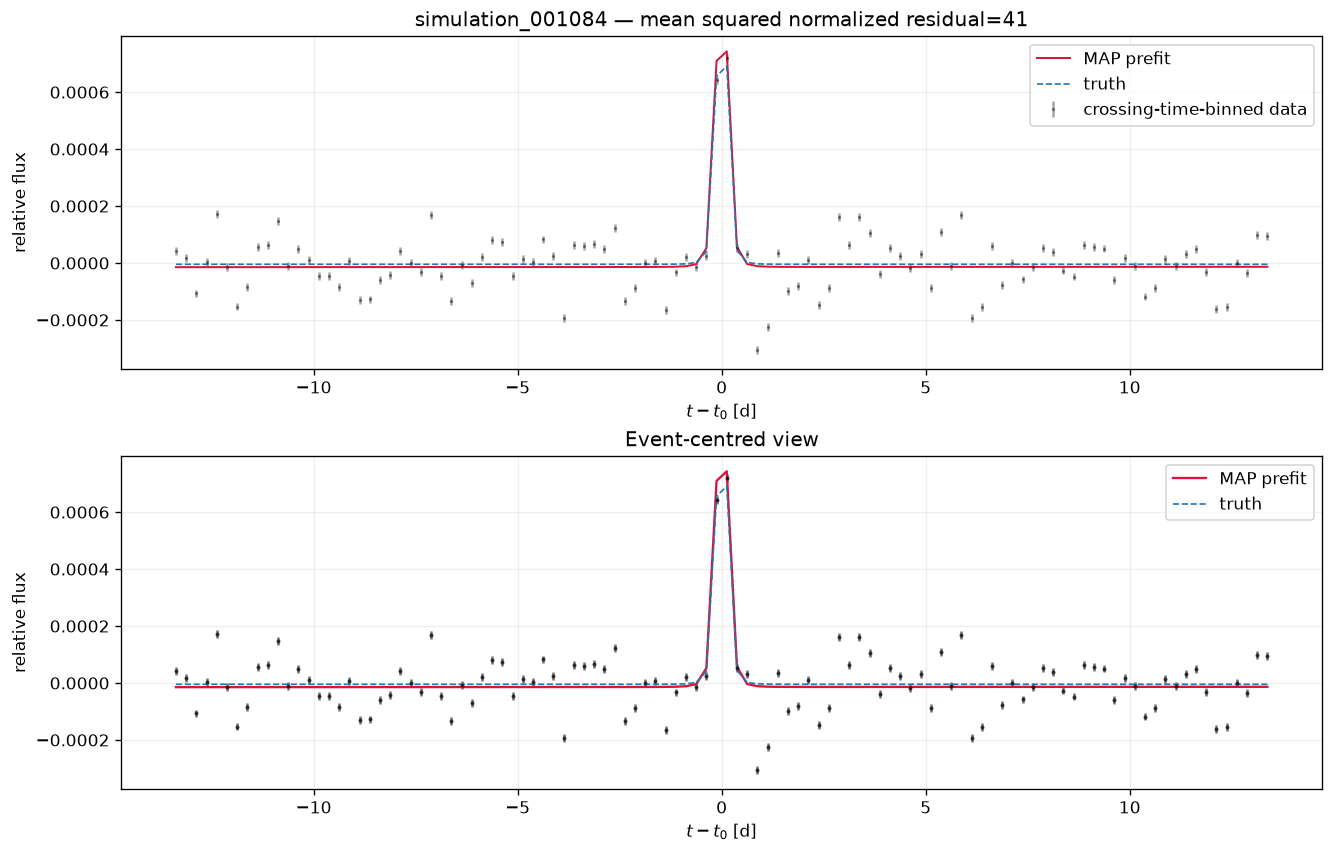

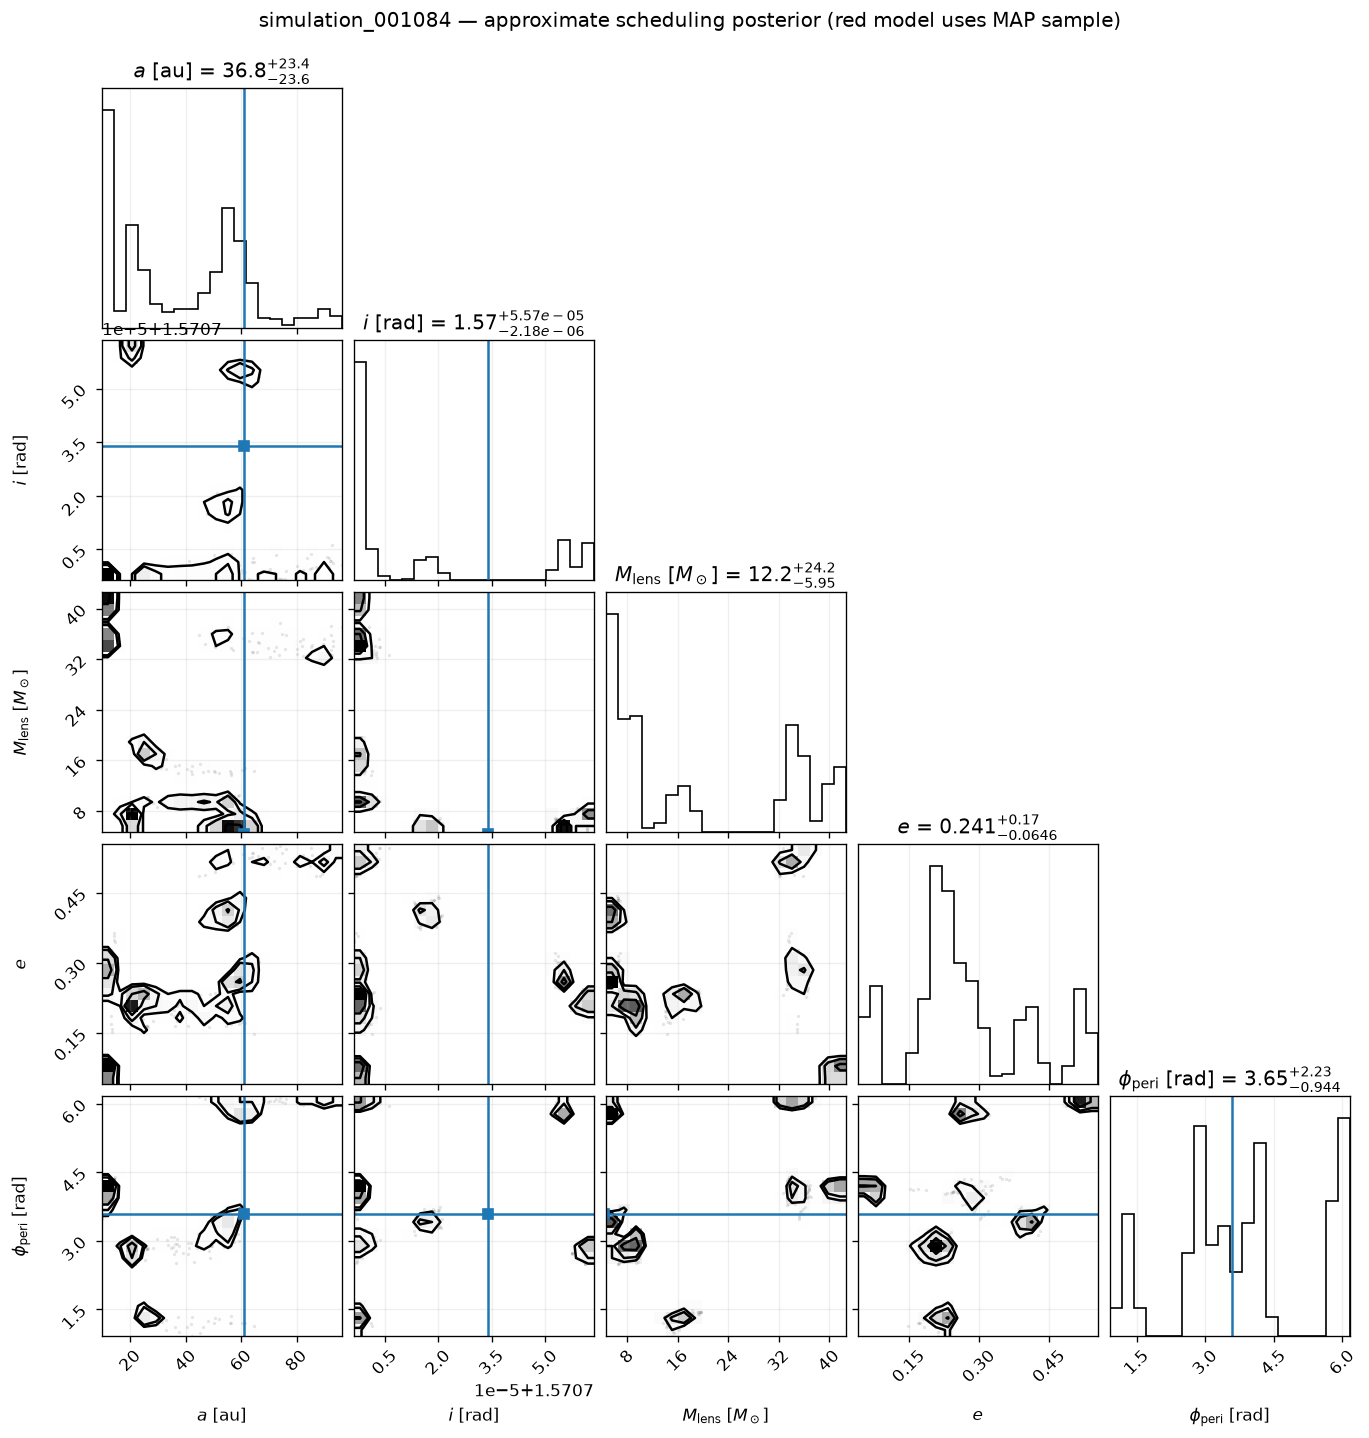

In [5]:
def show_prefit(index):
    """Show full and event-centred photometry plus a posterior corner plot."""
    row = review.iloc[index]
    data = curve_data(row)
    offset = data['times'] - float(row['peak_time'])
    residual = (data['flux'] - data['fit_model']) / data['err']
    chi2_per_point = np.mean(residual**2)

    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharey=True, constrained_layout=True)
    axes[0].errorbar(offset, data['flux'], yerr=data['err'], fmt='.', ms=2, alpha=0.35, color='black', label='crossing-time-binned data')
    axes[0].plot(offset, data['fit_model'], color='crimson', lw=1.2, label='MAP prefit')
    axes[0].plot(offset, data['truth_model'], color='tab:blue', lw=1.0, ls='--', label='truth')
    axes[0].set(xlabel=r'$t-t_0$ [d]', ylabel='relative flux', title=f"{row['simulation_id']} — mean squared normalized residual={chi2_per_point:.3g}")
    axes[0].legend(loc='best')
    window = max(0.25, 4.0 * float(row['tau_eff']))
    keep = np.abs(offset) <= window
    axes[1].errorbar(offset[keep], data['flux'][keep], yerr=data['err'][keep], fmt='.', ms=3, alpha=0.55, color='black')
    axes[1].plot(offset[keep], data['fit_model'][keep], color='crimson', lw=1.4, label='MAP prefit')
    axes[1].plot(offset[keep], data['truth_model'][keep], color='tab:blue', lw=1.0, ls='--', label='truth')
    axes[1].set(xlabel=r'$t-t_0$ [d]', ylabel='relative flux', title='Event-centred view')
    axes[1].legend(loc='best')

    samples = posterior_samples(row)
    fig = corner.corner(samples, labels=LABELS, truths=truth_vector(row), truth_color='tab:blue', color='black', show_titles=True, title_fmt='.3g')
    fig.suptitle(f"{row['simulation_id']} — approximate scheduling posterior (red model uses MAP sample)", y=1.02)
    plt.show()

show_prefit(0)

To step through all selected systems, run `show_prefit(index)` for any index from 0 to 99.  The following loop renders all 100 diagnostics, but is deliberately left commented because it produces a large notebook output.

```python
for index in range(len(review)):
    show_prefit(index)
```